# Cricket Player Performance Prediction Using Ridge and Lasso Regression
## ML lifecycle project through exploratory data analysis

**Machine Learning (25SC2107E) · Academic year 2026–2027**  
**Team 1 · Section 5**  
M Jashwanth Reddy (2520030236) · G Akshay (2520030363)  
**Guide:** Rani M

This project uses the supplied **match_data.csv** to study cricket batting performance. It completes the ML lifecycle through exploratory data analysis (EDA): problem definition, data collection, data understanding, initial preparation and EDA. Ridge and Lasso are proposed for a later phase; no models, data splits or evaluation scores are produced here.

The original abstract described football player ratings. The selected input instead contains cricket deliveries and no rating column. Therefore, the project is adapted to **runs scored by a player in a batting innings**, a numeric performance measure derived from recorded batting runs. This is a batting project, not an overall rating of batting, bowling and fielding ability.

| ML lifecycle stage | Completed work |
|---|---|
| 1 Problem definition | Batting objective, target, observation unit and scope |
| 2 Data collection | Preserve supplied CSV and record its fingerprint |
| 3 Data understanding | Schema, coverage, missingness and delivery audit |
| 4 Initial preparation | Dates, structural blanks, delivery indicators and batting-innings aggregation |
| 5 EDA | Univariate, bivariate and multivariate analysis, charts and findings |
| Future work | Historical features, temporal splitting, fitted preprocessing, Ridge/Lasso, evaluation and deployment |

Data understanding, cleaning and EDA inform each other. The stages below present that iterative work in a readable sequence.

## 1 Problem definition

**Objective:** Understand how batting-innings runs vary across players, seasons and innings, and determine what data preparation is needed for a later regression study.

**Target:** `innings_runs`, the sum of `runs_off_bat` for a batter in one match innings. Extras are not credited to the batter. A score of zero is a valid observation and remains in the analysis.

**Observation unit:** The source has one record per recorded delivery. The player-level analysis has one row per match, innings, batting team and player who appears as striker or non-striker. This includes observed non-strikers with no recorded striker deliveries. It does not manufacture observations for squad members who did not bat.

**Future prediction question:** Before a player's innings begins, how many runs might they score, using prior performances and available match context? The current innings' runs, balls, scoring rate, fours and sixes cannot be pre-innings inputs. They are used only for descriptive EDA here.

**Research questions**
1. What time span, seasons and match coverage are represented?
2. Which blanks represent absent events, and are there inconsistencies or ambiguous delivery labels?
3. How skewed are player innings scores, and how do opportunity and scoring rate relate to runs?
4. How do team innings totals and player scores vary across seasons and innings?
5. Which descriptive statistics overlap, and what does this imply for later modelling?

**Success criteria:** Reproducible loading, documented cleaning, reconciled aggregations, labelled charts and evidence-based conclusions. MAE, MSE and R² remain future metrics; no accuracy is claimed at the EDA stage.

## 2 Data collection and reproducibility

The sole input is the user-supplied `match_data.csv`. Its original Kaggle URL and licence were not supplied, so this report does not assign an unverified Kaggle page or ownership claim. The team names are consistent with IPL cricket, but the file has no explicit competition field.

The schema resembles [Cricsheet's Ashwin CSV format](https://cricsheet.org/format/csv_ashwin/). That documentation helps interpret delivery, runs, extras and dismissal columns; it does not establish the provenance of this particular export. In that format, absent extra events are blank. We verify that filling extra components with zero reconciles to total extras in this file.

The raw file is preserved unchanged. A SHA-256 fingerprint in `data/source_manifest.json` identifies the exact input. The notebook uses only the supplied cricket file; the earlier football dataset is not an input.

### Running the project
**Local:** Extract the ZIP, install `requirements.txt`, open this notebook in Jupyter, and run all cells from the extracted project directory.

**Google Colab:** Upload this notebook and upload `data/raw/match_data.csv` through Colab's Files panel. Then run all cells. If necessary, install dependencies with `%pip install pandas numpy matplotlib seaborn`. Generated files are stored in `results/`.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi":120,"axes.spines.top":False,"axes.spines.right":False})
RESULTS=Path("results")
FIGURES=RESULTS/"figures"
FIGURES.mkdir(parents=True,exist_ok=True)
def plot_done(name):
    plt.tight_layout()
    plt.savefig(FIGURES/f"{name}.png",dpi=150,bbox_inches="tight")
    plt.show()
    plt.close()

In [2]:
candidates=[Path("data/raw/match_data.csv"),Path("match_data.csv"),Path("/content/match_data.csv")]
path=next((p for p in candidates if p.is_file()),None)
if path is None:
    raise FileNotFoundError("Upload the supplied match_data.csv, then rerun.")
assert hashlib.sha256(path.read_bytes()).hexdigest()=="4e556f3d6f8c46afe2c66c924c0c9a72195133db5f3f660dc0748ac970c82536", "File differs from the analysed input; review changes before using a new snapshot."
# Preserve season labels such as 2020/21 and delivery identifiers as text.
raw=pd.read_csv(path,dtype={"season":"string","ball":"string"},low_memory=False)
display(pd.DataFrame({"rows":[len(raw)],"columns":[raw.shape[1]],"matches":[raw.match_id.nunique()]}))
display(raw.head().T)

,rows,columns,matches
0,243817,23,1024


,0,1,2,3,4
match_id,1370353,1370353,1370353,1370353,1370353
season,2023,2023,2023,2023,2023
start_date,2023-05-29,2023-05-29,2023-05-29,2023-05-29,2023-05-29
venue,"Narendra Modi Stadium, Ahmedabad","Narendra Modi Stadium, Ahmedabad","Narendra Modi Stadium, Ahmedabad","Narendra Modi Stadium, Ahmedabad","Narendra Modi Stadium, Ahmedabad"
innings,1,1,1,1,1
ball,0.1,0.2,0.3,0.4,0.5
batting_team,Gujarat Titans,Gujarat Titans,Gujarat Titans,Gujarat Titans,Gujarat Titans
bowling_team,Chennai Super Kings,Chennai Super Kings,Chennai Super Kings,Chennai Super Kings,Chennai Super Kings
striker,WP Saha,WP Saha,WP Saha,Shubman Gill,WP Saha
non_striker,Shubman Gill,Shubman Gill,Shubman Gill,WP Saha,Shubman Gill


## 3 Data understanding

### Data dictionary
| Fields | Meaning | Treatment |
|---|---|---|
| match_id, cricsheet_id | Match identifiers | Check agreement; never numeric performance predictors |
| season | Source season label, including labels like 2007/08 | Preserve as text |
| start_date | Match start date | Parse as date; derive calendar year separately |
| venue | Recorded venue name | Preserve labels; venue aliases may remain |
| innings | Innings index | Main EDA uses 1 and 2; later innings reported separately |
| ball | Over and delivery label | Keep as text; not a decimal duration or unique row key |
| batting_team, bowling_team | Team labels at the delivery | Preserve historical labels |
| striker, non_striker, bowler | Named players | Name-based grouping; no stable player registry supplied |
| runs_off_bat | Runs credited to striker | Sum for target |
| extras | Total extra runs | Sum with batting runs for team score |
| wides, noballs, byes, legbyes, penalty | Components of extras | Blank becomes zero after reconciliation |
| wicket_type, player_dismissed | Recorded dismissal or retirement event | Blank means no recorded event |
| other_wicket_type, other_player_dismissed | Optional second event on a delivery | Retain in raw file; audit availability |

`season` and calendar year are not interchangeable. We use the original season labels on season charts, ordered by the first observed match date.

In [3]:
schema=pd.DataFrame({"dtype":raw.dtypes.astype(str),"missing":raw.isna().sum(),"missing_pct":100*raw.isna().mean(),"distinct":raw.nunique()})
display(schema)
schema.to_csv(RESULTS/"schema_missingness.csv")
print("Source season labels:",raw.season.unique().tolist())
print("Recorded innings indices:",raw.innings.value_counts().sort_index().to_dict())
exact_duplicates=int(raw.duplicated().sum())
repeated_ball_keys=int(raw.duplicated(["match_id","innings","ball"]).sum())
print("Identical-looking additional rows:",exact_duplicates)
print("Additional repeated delivery labels:",repeated_ball_keys)
display(raw.loc[raw.duplicated(keep=False),["match_id","innings","ball","striker","runs_off_bat","extras"]])
raw.loc[raw.duplicated(["match_id","innings","ball"],keep=False)].to_csv(RESULTS/"ambiguous_delivery_labels.csv",index=False)

,dtype,missing,missing_pct,distinct
match_id,int64,0,0.000,1024
season,string,0,0.000,16
start_date,str,0,0.000,762
venue,str,0,0.000,56
innings,int64,0,0.000,6
ball,string,0,0.000,182
batting_team,str,0,0.000,18
bowling_team,str,0,0.000,18
striker,str,0,0.000,637
non_striker,str,0,0.000,626


Source season labels: ['2023', '2022', '2021', '2020/21', '2019', '2018', '2017', '2016', '2015', '2014', '2013', '2012', '2011', '2009/10', '2009', '2007/08']
Recorded innings indices: {1: 126125, 2: 117531, 3: 77, 4: 72, 5: 8, 6: 4}


Identical-looking additional rows: 2
Additional repeated delivery labels: 24


,match_id,innings,ball,striker,runs_off_bat,extras
2942,1359536,1,1.1,B Sai Sudharsan,0,0
2951,1359536,1,1.1,B Sai Sudharsan,0,0
205087,419152,1,3.1,SR Tendulkar,1,0
205096,419152,1,3.1,SR Tendulkar,1,0


## 4 Initial data preparation

**Delivery identity:** Retain every input row and assign a sequential `source_row_id`. Repeated labels and two identical-looking additional rows are preserved. Some equal labels occur nine rows apart, consistent with an export possibly shortening labels such as `1.10` to `1.1`. This is a hypothesis, not a verified repair. Removing them could delete genuine deliveries. The original delivery file would be required to resolve the ambiguity.

**Missing values:** Fill only extra-component blanks with zero. Preserve event blanks. No median imputation, encoding or scaling is fitted. Validate counts and extras before analysis.

**Innings scope:** Restrict the main analysis to innings 1 and 2. Later innings are consistent with tie-break innings in this T20-style data, but the explicit super-over metadata file is unavailable. They are saved separately rather than mixed into ordinary innings.

**Derived descriptive fields:** Team runs are batting runs plus extras. `non_wide_deliveries` counts striker deliveries without wides; it is a transparent exposure proxy, not a claim of exact official balls faced for every exceptional event. `runs_per_100_nonwide` is the corresponding scoring-rate proxy. Deliveries yielding four or six batting runs are labelled `four_run_events` and `six_run_events`: without a non-boundary flag, they cannot all be certified as boundaries.

**No automatic outlier removal:** High scores can be valid cricket outcomes. IQR flags are reported only for inspection. All zero scores remain.

In [4]:
df=raw.copy()
df["source_row_id"]=np.arange(len(df))
df["start_date"]=pd.to_datetime(df.start_date,errors="coerce")
extra_cols=["wides","noballs","byes","legbyes","penalty"]
df[extra_cols]=df[extra_cols].fillna(0)
checks=pd.Series({
    "invalid_dates":df.start_date.isna().sum(),
    "negative_run_or_extra_rows":df[["runs_off_bat","extras"]+extra_cols].lt(0).any(axis=1).sum(),
    "extras_not_reconciled":df[extra_cols].sum(axis=1).ne(df.extras).sum(),
    "match_id_disagreement":df.match_id.ne(df.cricsheet_id).sum(),
    "missing_required_rows":df[["match_id","season","innings","striker","non_striker","batting_team","bowling_team","runs_off_bat","extras"]].isna().any(axis=1).sum(),
    "same_batting_and_bowling_team":df.batting_team.eq(df.bowling_team).sum()
},name="flagged_rows")
display(checks.to_frame())
assert checks.eq(0).all(),"Review quality exceptions before continuing."
df["total_runs"]=df.runs_off_bat+df.extras
regular=df.loc[df.innings.isin([1,2])].copy()
extra_innings=df.loc[~df.innings.isin([1,2])].copy()
regular["non_wide_delivery"]=regular.wides.eq(0).astype(int)
regular["four_run_event"]=regular.runs_off_bat.eq(4).astype(int)
regular["six_run_event"]=regular.runs_off_bat.eq(6).astype(int)
regular["zero_bat_run_nonwide"]= (regular.runs_off_bat.eq(0)&regular.wides.eq(0)).astype(int)
extra_innings.to_csv(RESULTS/"additional_innings.csv",index=False)
checks.to_csv(RESULTS/"quality_checks.csv")

,flagged_rows
invalid_dates,0
negative_run_or_extra_rows,0
extras_not_reconciled,0
match_id_disagreement,0
missing_required_rows,0
same_batting_and_bowling_team,0


### Constructing the player innings table
The aggregation uses striker runs but includes both observed batting partners in its roster. A non-striker who never appears as striker has zero recorded batting runs and zero striker exposure. This is different from adding absent squad players. Player names are used exactly as supplied; unverified name variants are not merged.

Within each match and innings, date, teams and season must be consistent. Reconciliation checks verify that the aggregated player runs equal the retained delivery batting runs and that team totals include extras exactly once.

In [5]:
context=["match_id","innings","season","start_date","venue","batting_team","bowling_team"]
consistency=regular.groupby(["match_id","innings"])[context[2:]].nunique()
assert consistency.le(1).all().all(),"Conflicting innings context."
roster=pd.concat([regular[context+[col]].rename(columns={col:"player"}) for col in ["striker","non_striker"]],ignore_index=True).drop_duplicates()
agg=regular.groupby(["match_id","innings","striker"],as_index=False).agg(
    innings_runs=("runs_off_bat","sum"),non_wide_deliveries=("non_wide_delivery","sum"),
    recorded_striker_deliveries=("source_row_id","size"),four_run_events=("four_run_event","sum"),
    six_run_events=("six_run_event","sum"),zero_bat_run_nonwide=("zero_bat_run_nonwide","sum")
).rename(columns={"striker":"player"})
bat=roster.merge(agg,on=["match_id","innings","player"],how="left",validate="one_to_one")
metrics=["innings_runs","non_wide_deliveries","recorded_striker_deliveries","four_run_events","six_run_events","zero_bat_run_nonwide"]
bat[metrics]=bat[metrics].fillna(0).astype(int)
bat["runs_per_100_nonwide"]=100*bat.innings_runs/bat.non_wide_deliveries.where(bat.non_wide_deliveries.gt(0))
bat["zero_bat_run_share"]=bat.zero_bat_run_nonwide/bat.non_wide_deliveries.where(bat.non_wide_deliveries.gt(0))
team=regular.groupby(context,as_index=False).agg(team_runs=("total_runs","sum"),batting_runs=("runs_off_bat","sum"),extras=("extras","sum"),recorded_deliveries=("source_row_id","size"))
assert bat.innings_runs.sum()==regular.runs_off_bat.sum()
assert team.team_runs.sum()==regular.total_runs.sum()
assert not bat.duplicated(["match_id","innings","player"]).any()
bat.to_csv(RESULTS/"batting_innings_eda.csv",index=False)
team.to_csv(RESULTS/"team_innings_eda.csv",index=False)
flow=pd.DataFrame({"stage":["Input deliveries retained","Main innings deliveries","Additional innings deliveries","Player batting innings","Team innings"],"rows":[len(raw),len(regular),len(extra_innings),len(bat),len(team)]})
display(flow)
display(bat[["player","season","innings","innings_runs","non_wide_deliveries","four_run_events","six_run_events"]].head())
flow.to_csv(RESULTS/"row_counts.csv",index=False)

,stage,rows
0,Input deliveries retained,243817
1,Main innings deliveries,243656
2,Additional innings deliveries,161
3,Player batting innings,15713
4,Team innings,2045


,player,season,innings,innings_runs,non_wide_deliveries,four_run_events,six_run_events
0,WP Saha,2023,1,54,39,5,1
1,Shubman Gill,2023,1,39,20,7,0
2,B Sai Sudharsan,2023,1,96,47,8,6
3,HH Pandya,2023,1,21,12,0,2
4,Rashid Khan,2023,1,0,2,0,0


## 5 Exploratory data analysis
### 5.1 Missingness and season coverage
The missingness plot describes the raw file. Event columns are sparse because the event usually does not occur. They should not be treated like randomly missing measurements. Season counts below are **distinct matches**, not delivery counts.

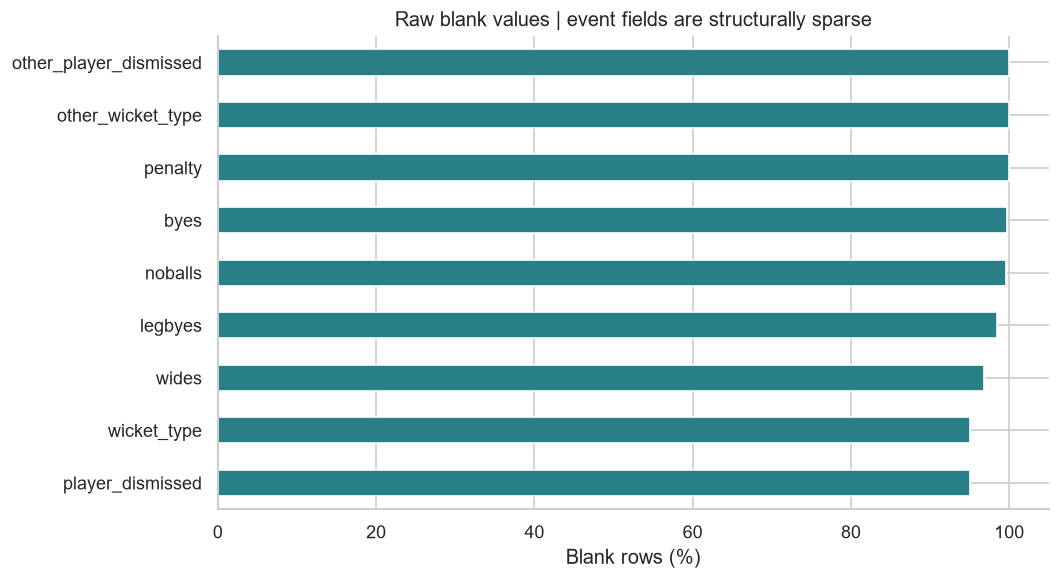

,matches,first_date,last_date,deliveries
season,,,,
2007/08,58,2008-04-18,2008-06-01,13489
2009,57,2009-04-18,2009-05-24,13595
2009/10,60,2010-03-12,2010-04-25,14489
2011,73,2011-04-08,2011-05-28,17013
2012,74,2012-04-04,2012-05-27,17767
2013,76,2013-04-03,2013-05-26,18152
2014,60,2014-04-16,2014-06-01,14288
2015,59,2015-04-08,2015-05-24,13641
2016,60,2016-04-09,2016-05-29,14096


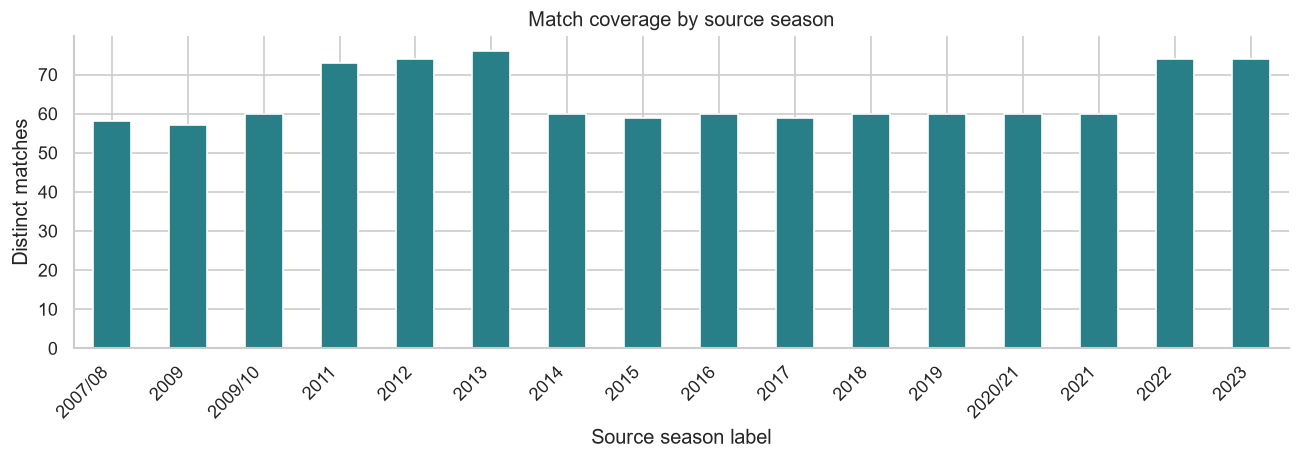

In [6]:
fig,ax=plt.subplots(figsize=(9,5))
schema.loc[schema.missing.gt(0),"missing_pct"].sort_values().plot.barh(ax=ax,color="#287f87")
ax.set(title="Raw blank values | event fields are structurally sparse",xlabel="Blank rows (%)",ylabel="")
plot_done("01_missingness")
season=regular.groupby("season").agg(matches=("match_id","nunique"),first_date=("start_date","min"),last_date=("start_date","max"),deliveries=("source_row_id","size")).sort_values("first_date")
order=season.index.tolist()
display(season)
fig,ax=plt.subplots(figsize=(11,4))
season.matches.plot.bar(ax=ax,color="#287f87")
ax.set(title="Match coverage by source season",xlabel="Source season label",ylabel="Distinct matches")
plt.xticks(rotation=45,ha="right")
plot_done("02_season_coverage")
season.to_csv(RESULTS/"season_coverage.csv")

### 5.2 Distribution of player innings runs
Runs are nonnegative and may be strongly skewed. A zero-run innings can occur even without a dismissal. We therefore call these **zero-run innings**, not ducks. The exposure and scoring-rate measures describe opportunity and scoring pace; they are not interchangeable with cricket batting average.

,count,mean,std,min,25%,50%,75%,max
innings_runs,"15,713.000",19.420,21.219,0.000,3.000,12.000,28.000,175.000
non_wide_deliveries,"15,713.000",15.020,13.592,0.000,4.000,11.000,22.000,73.000
four_run_events,"15,713.000",1.760,2.298,0.000,0.000,1.000,3.000,19.000
six_run_events,"15,713.000",0.749,1.332,0.000,0.000,0.000,1.000,17.000
runs_per_100_nonwide,"15,396.000",111.565,67.426,0.000,66.667,110.000,150.000,600.000


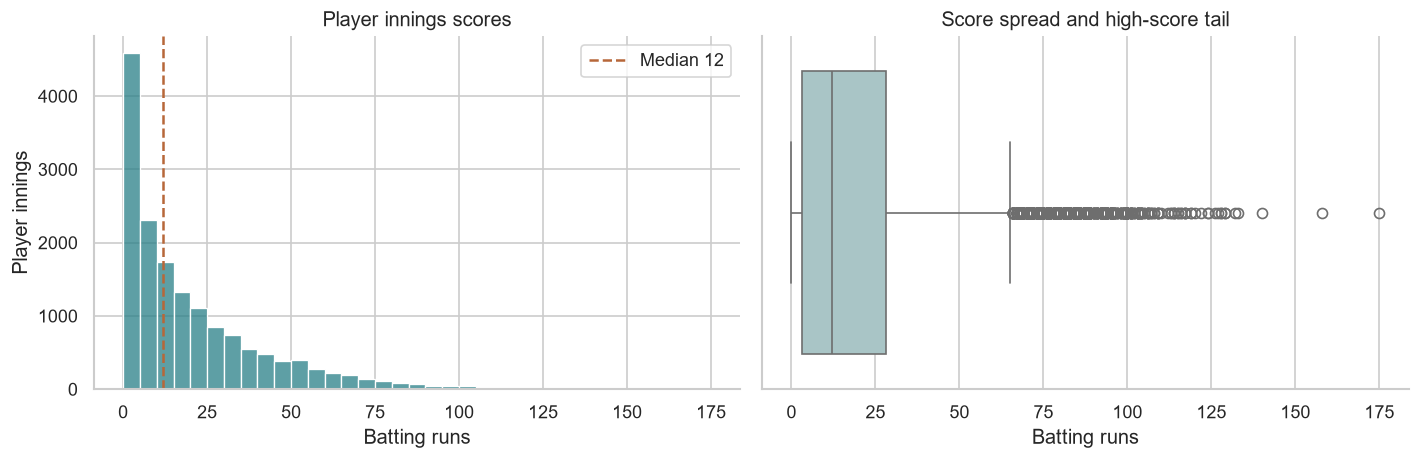

Upper IQR fence: 65.5; scores above it: 725. All retained.


In [7]:
display(bat[["innings_runs","non_wide_deliveries","four_run_events","six_run_events","runs_per_100_nonwide"]].describe().T)
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.histplot(data=bat,x="innings_runs",binwidth=5,ax=axes[0],color="#287f87")
axes[0].axvline(bat.innings_runs.median(),color="#b76739",ls="--",label=f"Median {bat.innings_runs.median():.0f}")
axes[0].legend()
axes[0].set(title="Player innings scores",xlabel="Batting runs",ylabel="Player innings")
sns.boxplot(data=bat,x="innings_runs",ax=axes[1],color="#a4c9cb")
axes[1].set(title="Score spread and high-score tail",xlabel="Batting runs")
plot_done("03_target_distribution")
q1,q3=bat.innings_runs.quantile([.25,.75]); upper=q3+1.5*(q3-q1)
print(f"Upper IQR fence: {upper:.1f}; scores above it: {bat.innings_runs.gt(upper).sum():,}. All retained.")

### 5.3 Runs and batting opportunity
Players who remain at the crease have more opportunities to score. The association between current innings runs and current exposure is descriptive, and these completed-innings statistics would leak information into a pre-innings prediction model.

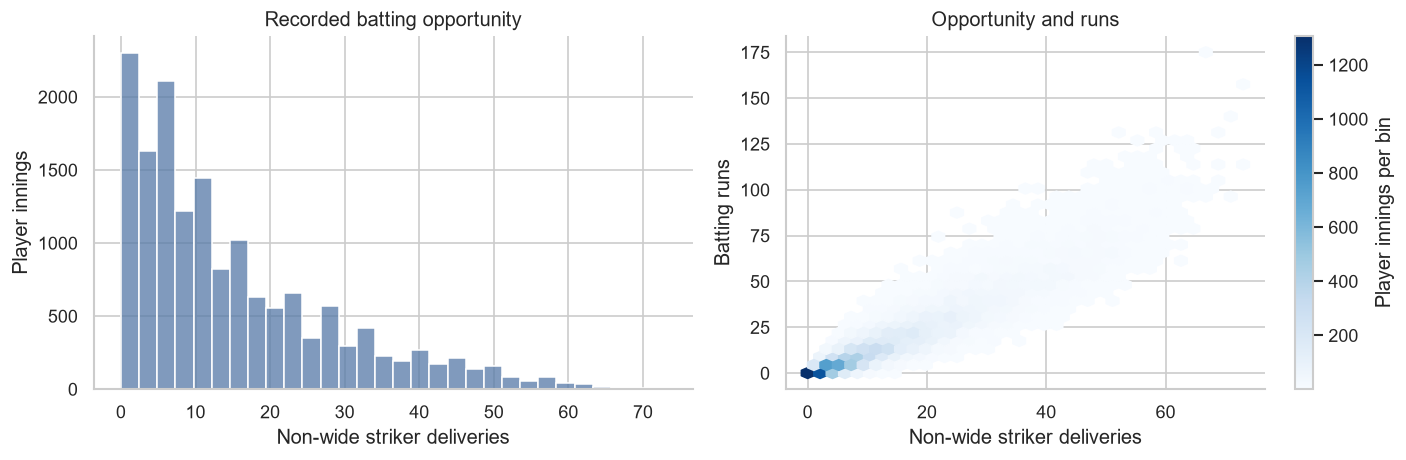

In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.histplot(data=bat,x="non_wide_deliveries",bins=30,ax=axes[0],color="#5679a7")
axes[0].set(title="Recorded batting opportunity",xlabel="Non-wide striker deliveries",ylabel="Player innings")
hb=axes[1].hexbin(bat.non_wide_deliveries,bat.innings_runs,gridsize=35,mincnt=1,cmap="Blues")
axes[1].set(title="Opportunity and runs",xlabel="Non-wide striker deliveries",ylabel="Batting runs")
fig.colorbar(hb,ax=axes[1],label="Player innings per bin")
plot_done("04_exposure_and_runs")

### 5.4 Seasons and team innings totals
Each point in the team-total boxplot is a team innings, not a match total. Shortened, incomplete and chase innings remain present; a low total does not necessarily mean poor performance. No target or scheduled-overs metadata is available to adjust these cases reliably.

,player_innings,mean_runs,median_runs,zero_run_pct
season,,,,
2007/08,895,18.781,12.000,10.056
2009,901,17.030,10.000,13.208
2009/10,937,18.927,13.000,10.245
2011,1075,18.538,12.000,11.349
2012,1123,18.988,12.000,8.192
2013,1183,18.112,12.000,11.074
2014,892,20.092,13.000,8.408
2015,900,19.343,13.000,10.000
2016,883,20.342,11.000,8.947


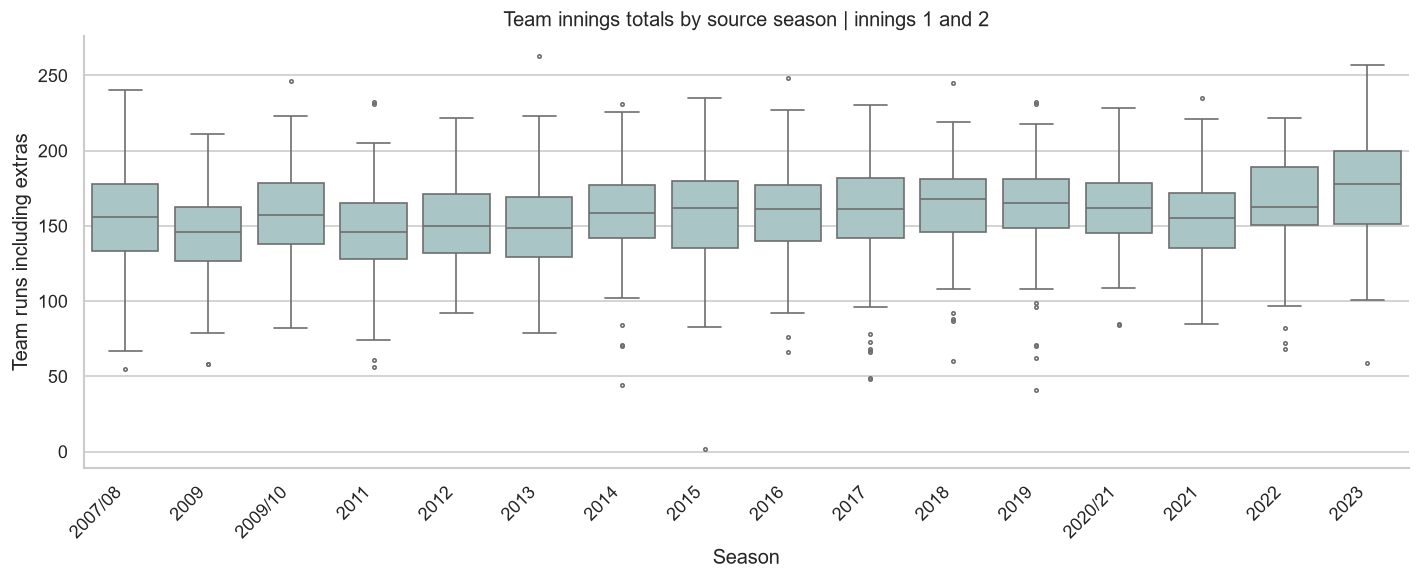

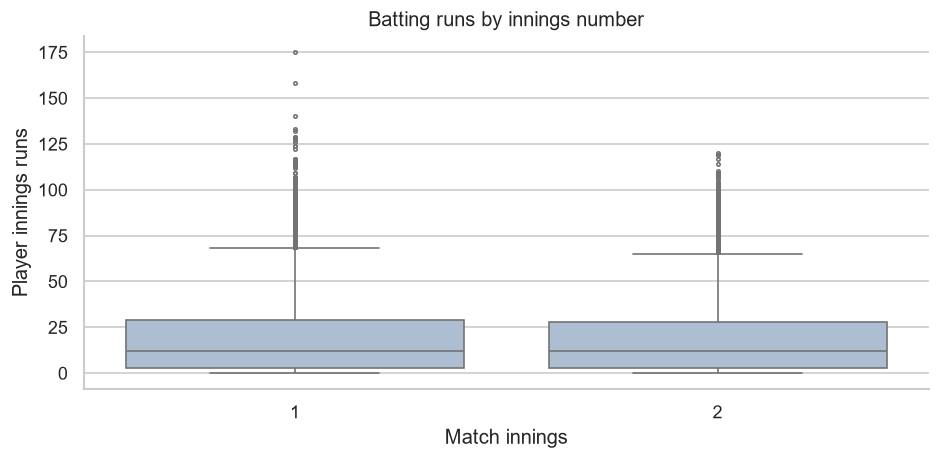

In [9]:
season_scores=bat.groupby("season").agg(player_innings=("innings_runs","size"),mean_runs=("innings_runs","mean"),median_runs=("innings_runs","median"),zero_run_pct=("innings_runs",lambda s:100*s.eq(0).mean())).reindex(order)
display(season_scores)
fig,ax=plt.subplots(figsize=(12,5))
sns.boxplot(data=team,x="season",y="team_runs",order=order,color="#a4c9cb",fliersize=2,ax=ax)
ax.set(title="Team innings totals by source season | innings 1 and 2",xlabel="Season",ylabel="Team runs including extras")
plt.xticks(rotation=45,ha="right")
plot_done("05_season_team_totals")
fig,ax=plt.subplots(figsize=(8,4))
sns.boxplot(data=bat,x="innings",y="innings_runs",color="#a8bdd8",fliersize=2,ax=ax)
ax.set(title="Batting runs by innings number",xlabel="Match innings",ylabel="Player innings runs")
plot_done("06_innings_comparison")
season_scores.to_csv(RESULTS/"season_batting_summary.csv")

### 5.5 Delivery scoring, extras and dismissal events
Delivery scoring includes zero batting runs even when extras are scored. Extras are team runs, not player batting runs. Dismissal-type counts are shown as recorded events and include retirement events; they are not bowler wicket totals. Run-outs and retired-hurt events must not be credited as bowler wickets.

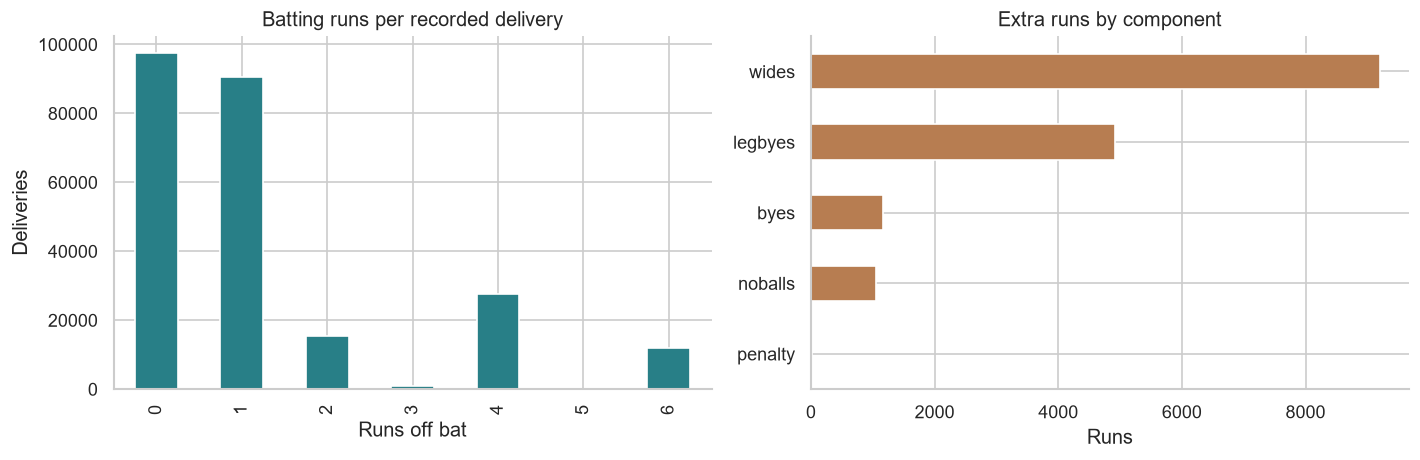

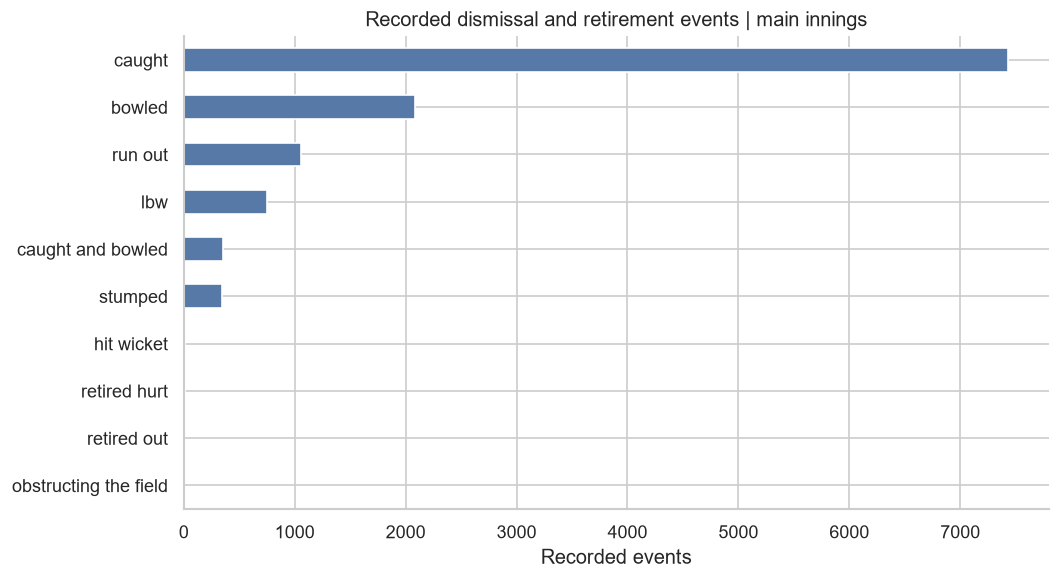

In [10]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
regular.runs_off_bat.value_counts().sort_index().plot.bar(ax=axes[0],color="#287f87")
axes[0].set(title="Batting runs per recorded delivery",xlabel="Runs off bat",ylabel="Deliveries")
regular[extra_cols].sum().sort_values().plot.barh(ax=axes[1],color="#b77d51")
axes[1].set(title="Extra runs by component",xlabel="Runs",ylabel="")
plot_done("07_scoring_and_extras")
events=regular.wicket_type.dropna().value_counts()
fig,ax=plt.subplots(figsize=(9,5))
events.sort_values().plot.barh(ax=ax,color="#5679a7")
ax.set(title="Recorded dismissal and retirement events | main innings",xlabel="Recorded events",ylabel="")
plot_done("08_dismissal_events")
events.rename("events").to_csv(RESULTS/"dismissal_events.csv")

### 5.6 Comparing player histories
This chart ranks **total recorded batting runs**, which rewards both longevity and scoring. The table includes innings counts and mean runs per observed innings. Mean runs per innings is not official batting average, whose denominator is dismissals. These full-history summaries are EDA outputs, not features available before each historical match.

,observed_innings,total_runs,mean_runs_per_innings,median_runs,non_wide_deliveries
player,,,,,
V Kohli,229,7263,31.716,25.000,5586
S Dhawan,216,6617,30.634,25.500,5203
DA Warner,176,6397,36.347,34.500,4572
RG Sharma,238,6211,26.097,19.000,4776
SK Raina,200,5528,27.640,23.000,4043
AB de Villiers,170,5162,30.365,21.500,3403
MS Dhoni,218,5082,23.312,21.000,3739
CH Gayle,141,4965,35.213,23.000,3333
RV Uthappa,197,4952,25.137,22.000,3799


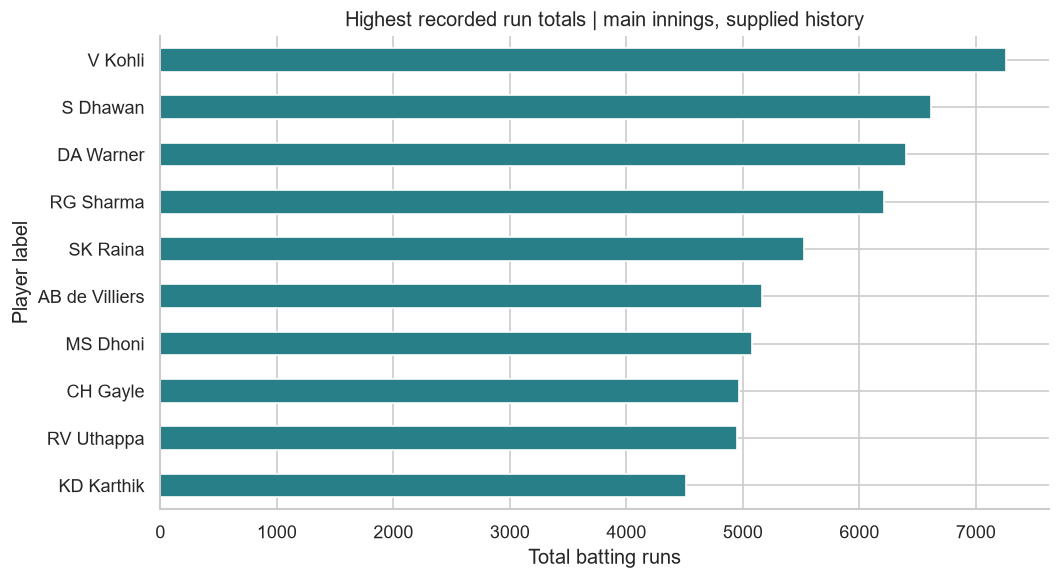

In [11]:
players=bat.groupby("player").agg(observed_innings=("innings_runs","size"),total_runs=("innings_runs","sum"),mean_runs_per_innings=("innings_runs","mean"),median_runs=("innings_runs","median"),non_wide_deliveries=("non_wide_deliveries","sum")).sort_values("total_runs",ascending=False)
display(players.head(15))
fig,ax=plt.subplots(figsize=(9,5))
players.total_runs.head(10).sort_values().plot.barh(ax=ax,color="#287f87")
ax.set(title="Highest recorded run totals | main innings, supplied history",xlabel="Total batting runs",ylabel="Player label")
plot_done("09_player_run_totals")
players.to_csv(RESULTS/"player_history_summary.csv")

### 5.7 Correlations and scoring-rate sensitivity
The heatmap uses completed-innings descriptive measurements. Several relationships are partly mathematical: runs contribute directly to the scoring-rate numerator, and four-run and six-run events contribute to total runs. High correlations here are **not** model validation or evidence of pre-match predictive value. Pearson correlations use available pairs; a zero exposure gives an undefined scoring rate.

We compare scoring-rate summaries at 1, 10 and 20 non-wide deliveries. This makes sensitivity to very short innings visible. The full target distribution remains unfiltered.

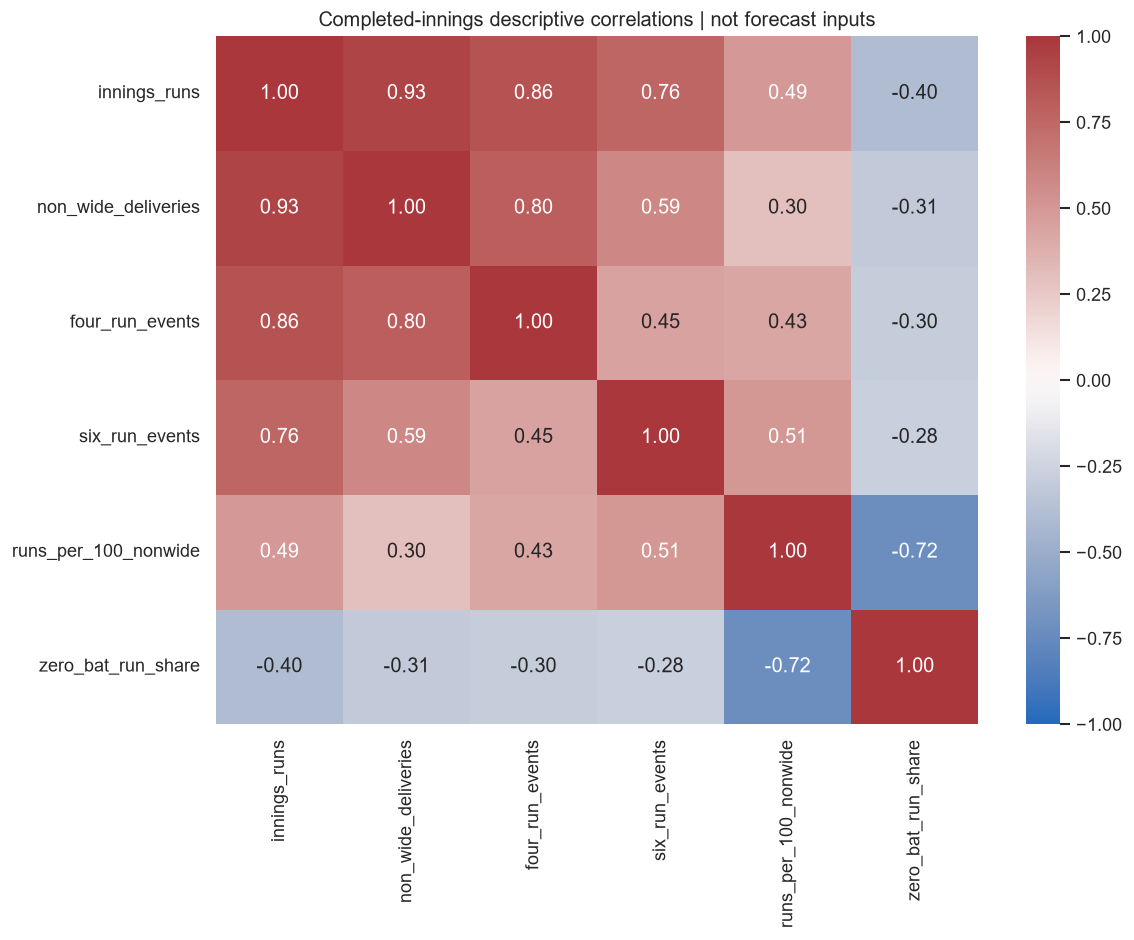

,min_nonwide_deliveries,player_innings,median_runs,median_runs_per_100_nonwide,mean_runs_per_100_nonwide
0,1,15396,13.000,110.000,111.565
1,10,8449,27.000,126.829,129.963
2,20,4534,41.000,131.818,135.363


In [12]:
corr_cols=["innings_runs","non_wide_deliveries","four_run_events","six_run_events","runs_per_100_nonwide","zero_bat_run_share"]
corr=bat[corr_cols].corr()
fig,ax=plt.subplots(figsize=(10,8))
sns.heatmap(corr,annot=True,fmt=".2f",cmap="vlag",vmin=-1,vmax=1,center=0,ax=ax)
ax.set_title("Completed-innings descriptive correlations | not forecast inputs")
plot_done("10_correlations")
sens=[]
for threshold in [1,10,20]:
    subset=bat.loc[bat.non_wide_deliveries.ge(threshold)]
    sens.append({"min_nonwide_deliveries":threshold,"player_innings":len(subset),"median_runs":subset.innings_runs.median(),"median_runs_per_100_nonwide":subset.runs_per_100_nonwide.median(),"mean_runs_per_100_nonwide":subset.runs_per_100_nonwide.mean()})
sensitivity=pd.DataFrame(sens)
display(sensitivity)
corr.to_csv(RESULTS/"descriptive_correlations.csv")
sensitivity.to_csv(RESULTS/"exposure_sensitivity.csv",index=False)

## 6 Findings and conclusion
The following values are calculated from the supplied cricket file. They are descriptive findings, not Ridge or Lasso results.

In [13]:
findings=f"""
- **Coverage:** {len(raw):,} delivery records and {raw.shape[1]} input columns cover {raw.match_id.nunique():,} matches from {df.start_date.min():%d %B %Y} to {df.start_date.max():%d %B %Y}, across {len(season)} source seasons.
- **Quality:** All extra components reconcile to recorded total extras after interpreting blank components as zero. {exact_duplicates} identical-looking additional records and {repeated_ball_keys} repeated delivery labels are retained because delivery identity is ambiguous in the export.
- **Analysis population:** {len(regular):,} delivery rows from innings 1 and 2 produce {len(bat):,} observed player batting innings for {bat.player.nunique():,} player labels. {len(extra_innings):,} additional-innings rows are reported separately.
- **Target:** Mean runs per observed innings is {bat.innings_runs.mean():.2f}, median is {bat.innings_runs.median():.0f}, and maximum is {bat.innings_runs.max():.0f}. {bat.innings_runs.eq(0).mean():.1%} are zero-run innings; these are retained as valid outcomes.
- **Opportunity:** Runs and non-wide striker deliveries have Pearson r = {corr.loc['innings_runs','non_wide_deliveries']:.3f}. This is a same-innings association, not a usable pre-innings predictor.
- **Team runs:** Extras contribute {regular.extras.sum()/regular.total_runs.sum():.1%} of retained team runs. Crediting these to batters would overstate their performance.
- **Player totals:** The leading recorded player label by total runs is **{players.index[0]}**, with {players.iloc[0].total_runs:,.0f} runs from {players.iloc[0].observed_innings:,.0f} observed innings. This ranking reflects opportunity and career coverage as well as scoring.
- **Scoring-rate sensitivity:** The median scoring-rate proxy is {sensitivity.iloc[0].median_runs_per_100_nonwide:.2f} for at least one non-wide delivery and {sensitivity.iloc[2].median_runs_per_100_nonwide:.2f} for at least twenty. Exposure filters change the population and must accompany comparisons.

**Conclusion:** The supplied file supports cricket batting EDA and a later player-innings regression study. The target is innings runs, not a provider rating. Skewed scores, repeated player histories, short innings and ambiguous delivery labels require care. The completed project ends at EDA.
"""
display(Markdown(findings))
(RESULTS/"findings.md").write_text(findings,encoding="utf-8")


- **Coverage:** 243,817 delivery records and 23 input columns cover 1,024 matches from 18 April 2008 to 29 May 2023, across 16 source seasons.
- **Quality:** All extra components reconcile to recorded total extras after interpreting blank components as zero. 2 identical-looking additional records and 24 repeated delivery labels are retained because delivery identity is ambiguous in the export.
- **Analysis population:** 243,656 delivery rows from innings 1 and 2 produce 15,713 observed player batting innings for 641 player labels. 161 additional-innings rows are reported separately.
- **Target:** Mean runs per observed innings is 19.42, median is 12, and maximum is 175. 10.6% are zero-run innings; these are retained as valid outcomes.
- **Opportunity:** Runs and non-wide striker deliveries have Pearson r = 0.932. This is a same-innings association, not a usable pre-innings predictor.
- **Team runs:** Extras contribute 5.1% of retained team runs. Crediting these to batters would overstate their performance.
- **Player totals:** The leading recorded player label by total runs is **V Kohli**, with 7,263 runs from 229 observed innings. This ranking reflects opportunity and career coverage as well as scoring.
- **Scoring-rate sensitivity:** The median scoring-rate proxy is 110.00 for at least one non-wide delivery and 131.82 for at least twenty. Exposure filters change the population and must accompany comparisons.

**Conclusion:** The supplied file supports cricket batting EDA and a later player-innings regression study. The target is innings runs, not a provider rating. Skewed scores, repeated player histories, short innings and ambiguous delivery labels require care. The completed project ends at EDA.


1730

## 7 Limitations and future work

**Dataset provenance:** The file is supplied locally. Its exact upstream page, release version and licence are unverified. Cricsheet format documentation is an interpretation reference only.

**Identity and coverage:** Player names may contain aliases, and historical team and venue names are preserved. The player roster covers observed batting participants, not full squads. Matches without deliveries, missing matches, and missing portions of innings cannot be ruled out from this file alone.

**Exceptional events:** The delivery label is ambiguous for some rows. Scoring-rate exposure and four/six event counts use explicit proxies because this export lacks all fields required to resolve special cases. Match outcomes, scheduled innings lengths, toss and batting-order metadata are not provided.

**Prediction timing:** A pre-innings model must use strictly earlier player history. Current innings exposure, scoring rate, boundary-like events and whole-career summaries would leak the target. Additional roster data may be required to predict for all selected players before a match.

**Later ML stages, not executed:** Construct lagged player summaries and a chronological validation design, keeping each match together. Fit any imputation, categorical encoding and scaling on training folds only. Compare a baseline with Ridge and Lasso, tune regularization on training data, and evaluate a reserved future test period using MAE, MSE and R². Both regressions can produce negative predictions for a nonnegative target, so prediction behaviour will need assessment. No such model is fitted here.

Because this EDA describes the full supplied history, a later test period selected from it will already have been explored. An additional, genuinely unseen later dataset would provide stronger final confirmation.

## References
1. User-supplied `match_data.csv`, received 17 September 2026; exact input identified by `data/source_manifest.json`.
2. User-supplied `ML ABSTRACT.docx`, original project concept and team information; the sport and target are adapted to the selected cricket data.
3. [Cricsheet Ashwin CSV format](https://cricsheet.org/format/csv_ashwin/), consulted 17 September 2026 for field interpretation. This file has fewer fields than the current documented format.

**Completed scope:** Problem definition → data collection → data understanding → initial preparation → EDA.